# STUDENT PERFORMANCE DATASET

## Aim
To perform Exploratory Data Analysis (EDA), data preprocessing,
70:30 training-testing split and classification on the UCI
Student Performance on an Entrance Examination dataset.

## Objective
To classify student performance in an entrance examination
using machine learning algorithms.

## Dataset Information
- Dataset: Student Performance on an Entrance Examination
- Source: UCI Machine Learning Repository
- Dataset ID: 582
- Total records: 666
- Target variable: Performance
- Classification type: Multiclass Classification

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [2]:
# Fetch Student Performance on an Entrance Examination dataset

student_data = fetch_ucirepo(id=582)

X = student_data.data.features.copy()
y = student_data.data.targets.copy()

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [3]:
print("Input features:")
display(X.head())

print("\nTarget variable:")
display(y.head())

Input features:


,Gender,Caste,coaching,Class_ten_education,twelve_education,medium,Class_X_Percentage,Class_XII_Percentage,Father_occupation,Mother_occupation,time
0,male,General,NO,SEBA,AHSEC,ENGLISH,Excellent,Excellent,DOCTOR,OTHERS,ONE
1,male,OBC,WA,SEBA,AHSEC,OTHERS,Excellent,Excellent,SCHOOL_TEACHER,HOUSE_WIFE,TWO
2,male,OBC,OA,OTHERS,CBSE,ENGLISH,Excellent,Excellent,BUSINESS,HOUSE_WIFE,TWO
3,male,General,WA,SEBA,AHSEC,OTHERS,Excellent,Excellent,SCHOOL_TEACHER,SCHOOL_TEACHER,ONE
4,male,General,OA,SEBA,CBSE,ENGLISH,Excellent,Excellent,COLLEGE_TEACHER,HOUSE_WIFE,TWO



Target variable:


,Performance
0,Excellent
1,Excellent
2,Excellent
3,Excellent
4,Excellent


In [4]:
print("Number of records:", X.shape[0])
print("Number of input features:", X.shape[1])
print("Number of target columns:", y.shape[1])

Number of records: 666
Number of input features: 11
Number of target columns: 1


In [5]:
# Combine input features and target

df = pd.concat(
    [X.reset_index(drop=True), y.reset_index(drop=True)],
    axis=1
)

print("Combined dataset:")
display(df.head())

Combined dataset:


,Gender,Caste,coaching,Class_ten_education,twelve_education,medium,Class_X_Percentage,Class_XII_Percentage,Father_occupation,Mother_occupation,time,Performance
0,male,General,NO,SEBA,AHSEC,ENGLISH,Excellent,Excellent,DOCTOR,OTHERS,ONE,Excellent
1,male,OBC,WA,SEBA,AHSEC,OTHERS,Excellent,Excellent,SCHOOL_TEACHER,HOUSE_WIFE,TWO,Excellent
2,male,OBC,OA,OTHERS,CBSE,ENGLISH,Excellent,Excellent,BUSINESS,HOUSE_WIFE,TWO,Excellent
3,male,General,WA,SEBA,AHSEC,OTHERS,Excellent,Excellent,SCHOOL_TEACHER,SCHOOL_TEACHER,ONE,Excellent
4,male,General,OA,SEBA,CBSE,ENGLISH,Excellent,Excellent,COLLEGE_TEACHER,HOUSE_WIFE,TWO,Excellent


In [6]:
target_column = y.columns[0]

print("Target column:", target_column)

print("\nPerformance class distribution:")
print(y[target_column].value_counts())

print("\nNumber of performance classes:")
print(y[target_column].nunique())

Target column: Performance

Performance class distribution:
Performance
Good         210
Vg           198
Average      157
Excellent    101
Name: count, dtype: int64

Number of performance classes:
4


In [7]:
df.info

<bound method DataFrame.info of      Gender    Caste coaching Class_ten_education twelve_education   medium  \
0      male  General       NO                SEBA            AHSEC  ENGLISH   
1      male      OBC       WA                SEBA            AHSEC   OTHERS   
2      male      OBC       OA              OTHERS             CBSE  ENGLISH   
3      male  General       WA                SEBA            AHSEC   OTHERS   
4      male  General       OA                SEBA             CBSE  ENGLISH   
..      ...      ...      ...                 ...              ...      ...   
661  female       ST       WA                SEBA            AHSEC  ENGLISH   
662    male       ST       WA                SEBA            AHSEC  ENGLISH   
663    male       ST       WA                SEBA             CBSE  ENGLISH   
664    male       ST       WA                SEBA            AHSEC  ENGLISH   
665  female       ST       NO                SEBA             CBSE  ENGLISH   

    Class_X_Percent

In [8]:
print("Dataset statistical summary:")
display(df.describe(include="all"))

Dataset statistical summary:


,Gender,Caste,coaching,Class_ten_education,twelve_education,medium,Class_X_Percentage,Class_XII_Percentage,Father_occupation,Mother_occupation,time,Performance
count,666,666,666,666,666,666,666,666,666,666,666,666
unique,2,4,3,3,3,3,4,4,8,9,6,4
top,male,General,WA,SEBA,AHSEC,ENGLISH,Excellent,Excellent,OTHERS,HOUSE_WIFE,TWO,Good
freq,355,329,449,396,368,536,511,398,277,442,368,210


In [9]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values in each column:
Gender                  0
Caste                   0
coaching                0
Class_ten_education     0
twelve_education        0
medium                  0
Class_X_Percentage      0
Class_XII_Percentage    0
Father_occupation       0
Mother_occupation       0
time                    0
Performance             0
dtype: int64

Total missing values:
0


In [10]:
print("Number of duplicate records:", df.duplicated().sum())

Number of duplicate records: 44


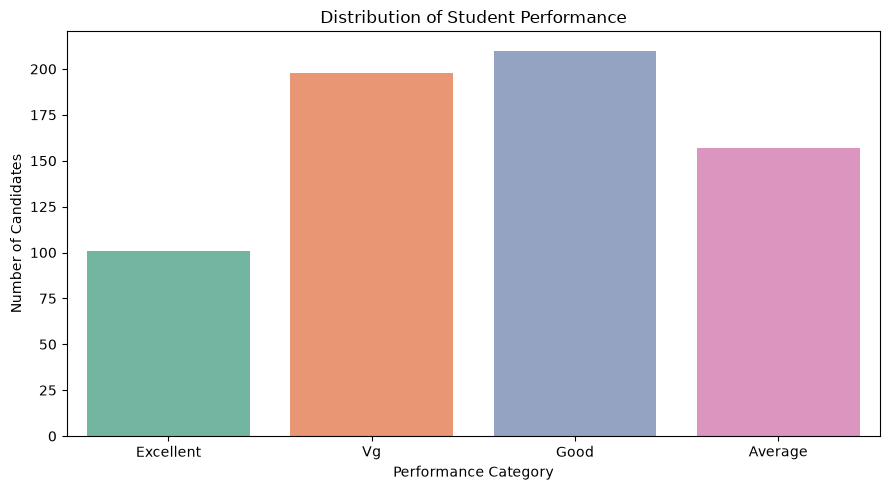

In [11]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x=target_column,
    hue=target_column,
    palette="Set2",
    legend=False
)

plt.title("Distribution of Student Performance")
plt.xlabel("Performance Category")
plt.ylabel("Number of Candidates")
plt.tight_layout()
plt.show()

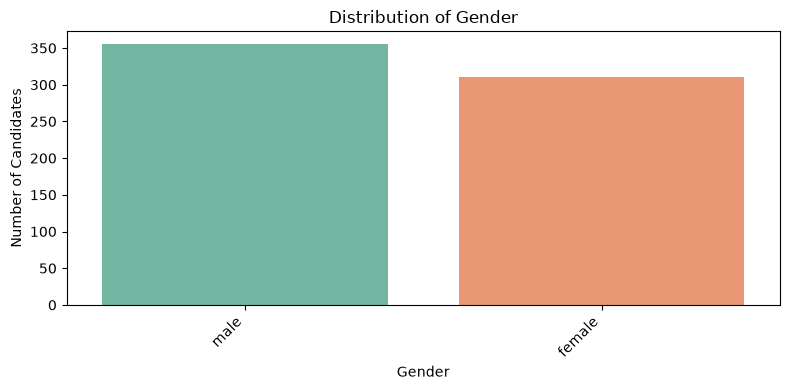

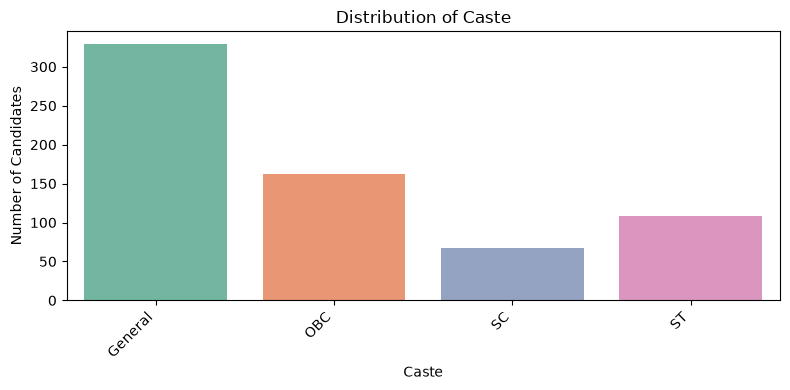

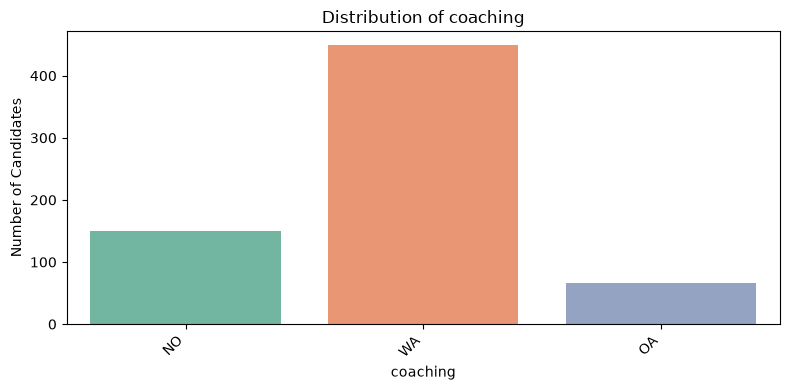

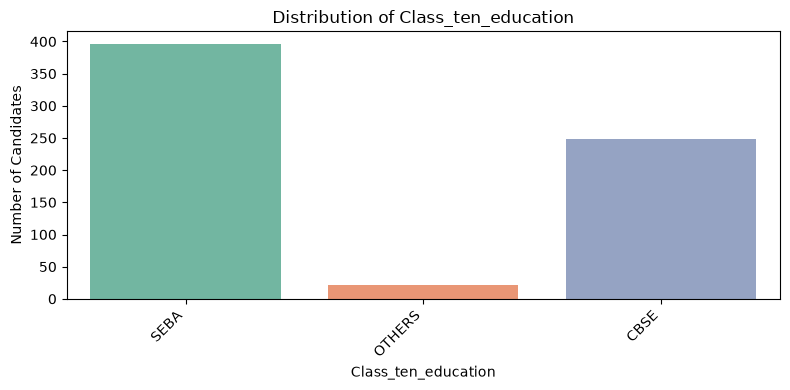

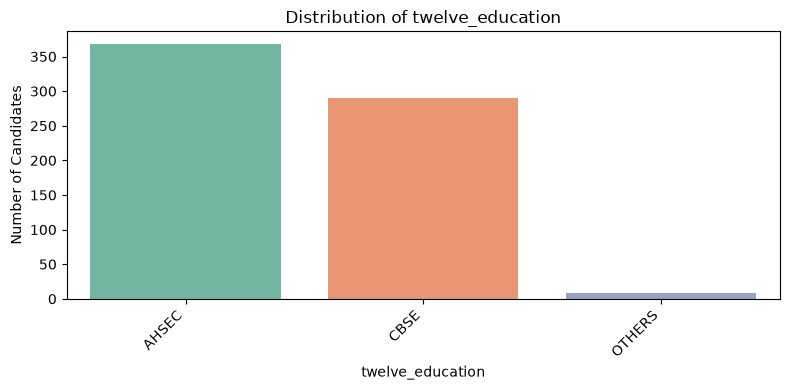

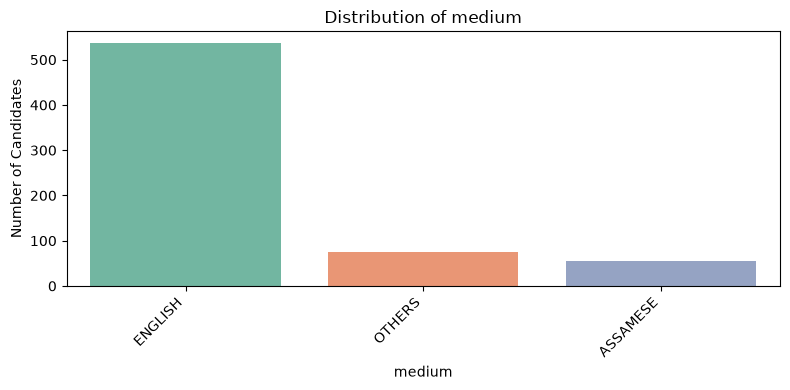

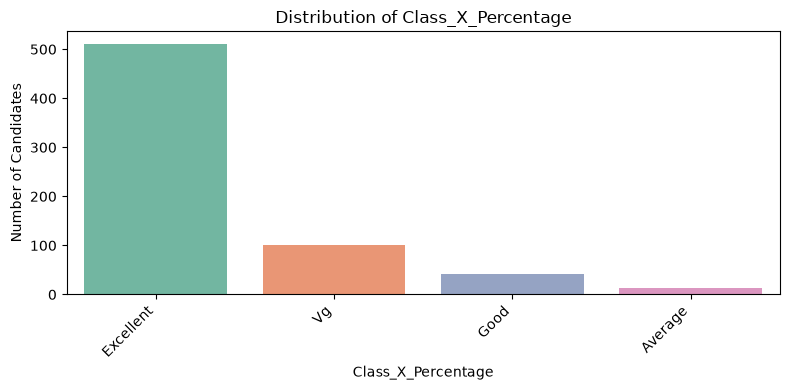

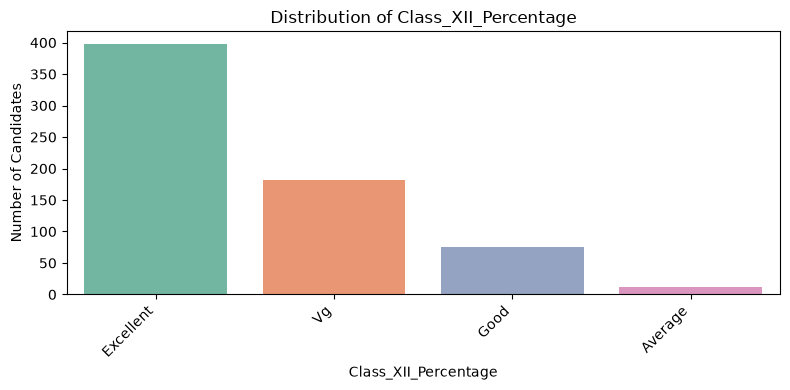

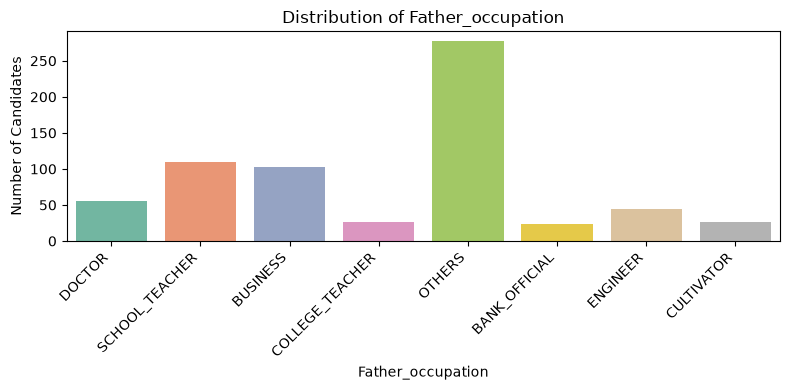

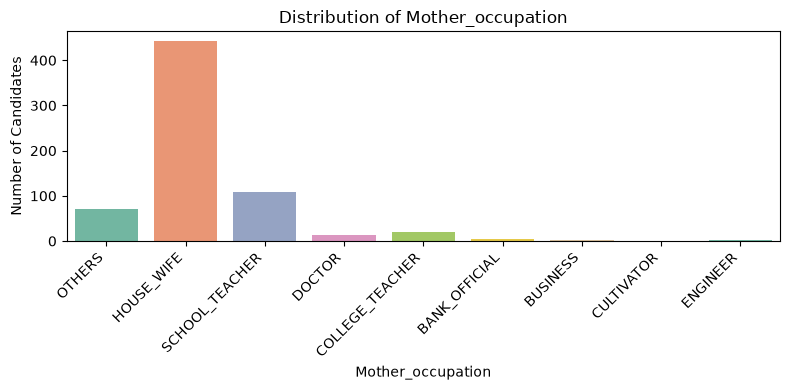

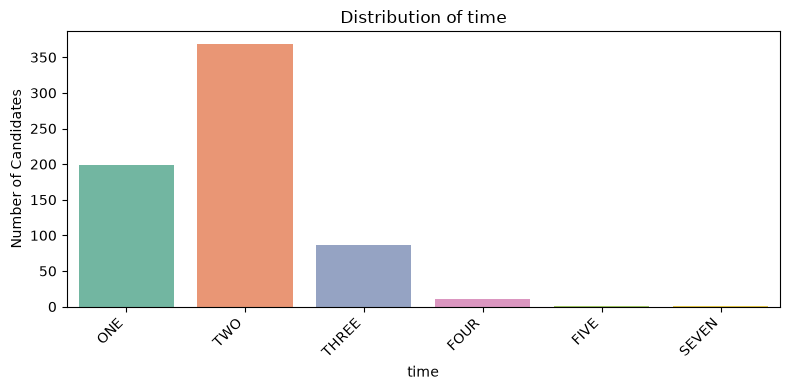

In [12]:
feature_columns = X.columns.tolist()

for column in feature_columns:

    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df,
        x=column,
        hue=column,
        palette="Set2",
        legend=False
    )

    plt.title("Distribution of " + column)
    plt.xlabel(column)
    plt.ylabel("Number of Candidates")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [14]:
# Compare selected features with student performance

for column in ["Gender", "coaching", "medium"]:
    if column in df.columns:
        print("\nPerformance distribution by", column)

        display(
            pd.crosstab(
                df[column],
                df[target_column],
                normalize="index"
            ).round(2)
        )


Performance distribution by Gender


Performance,Average,Excellent,Good,Vg
Gender,,,,
female,0.25,0.12,0.32,0.31
male,0.23,0.18,0.31,0.28



Performance distribution by coaching


Performance,Average,Excellent,Good,Vg
coaching,,,,
NO,0.27,0.13,0.35,0.25
OA,0.13,0.36,0.30,0.21
WA,0.24,0.13,0.31,0.33



Performance distribution by medium


Performance,Average,Excellent,Good,Vg
medium,,,,
ASSAMESE,0.39,0.14,0.34,0.12
ENGLISH,0.24,0.15,0.30,0.30
OTHERS,0.05,0.16,0.41,0.38


In [15]:
print("========== STUDENT PERFORMANCE EDA SUMMARY ==========")

print("Total Records:", df.shape[0])
print("Total Input Features:", X.shape[1])
print("Target Variable:", target_column)
print("Number of Performance Classes:", df[target_column].nunique())
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())

print("\nPerformance Distribution:")
print(df[target_column].value_counts())

========== STUDENT PERFORMANCE EDA SUMMARY ==========
Total Records: 666
Total Input Features: 11
Target Variable: Performance
Number of Performance Classes: 4
Missing Values: 0
Duplicate Records: 44

Performance Distribution:
Performance
Good         210
Vg           198
Average      157
Excellent    101
Name: count, dtype: int64


In [16]:
# Display duplicate records

duplicates = df[df.duplicated(keep=False)]

print("Total rows involved in duplicates:", len(duplicates))

display(duplicates.sort_values(by=list(df.columns)))

Total rows involved in duplicates: 81


,Gender,Caste,coaching,Class_ten_education,twelve_education,medium,Class_X_Percentage,Class_XII_Percentage,Father_occupation,Mother_occupation,time,Performance
122,female,General,NO,SEBA,AHSEC,ENGLISH,Excellent,Excellent,OTHERS,HOUSE_WIFE,ONE,Vg
157,female,General,NO,SEBA,AHSEC,ENGLISH,Excellent,Excellent,OTHERS,HOUSE_WIFE,ONE,Vg
410,female,General,NO,SEBA,AHSEC,ENGLISH,Excellent,Excellent,OTHERS,SCHOOL_TEACHER,ONE,Good
439,female,General,NO,SEBA,AHSEC,ENGLISH,Excellent,Excellent,OTHERS,SCHOOL_TEACHER,ONE,Good
361,female,General,NO,SEBA,AHSEC,ENGLISH,Excellent,Excellent,SCHOOL_TEACHER,SCHOOL_TEACHER,ONE,Good
...,...,...,...,...,...,...,...,...,...,...,...,...
569,male,ST,WA,CBSE,CBSE,ENGLISH,Excellent,Vg,OTHERS,HOUSE_WIFE,TWO,Average
615,male,ST,WA,CBSE,CBSE,ENGLISH,Excellent,Vg,OTHERS,HOUSE_WIFE,TWO,Average
616,male,ST,WA,CBSE,CBSE,ENGLISH,Excellent,Vg,OTHERS,HOUSE_WIFE,TWO,Average
650,male,ST,WA,SEBA,AHSEC,ENGLISH,Good,Good,SCHOOL_TEACHER,HOUSE_WIFE,THREE,Average


In [17]:
# Check whether duplicate input features have conflicting target labels

feature_duplicates = df[
    df.duplicated(subset=X.columns.tolist(), keep=False)
]

conflicting_groups = (
    feature_duplicates
    .groupby(X.columns.tolist(), dropna=False)["Performance"]
    .nunique()
)

print(
    "Number of repeated feature combinations with different "
    "performance labels:",
    (conflicting_groups > 1).sum()
)

Number of repeated feature combinations with different performance labels: 42


In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 666 entries, 0 to 665
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Gender                666 non-null    str  
 1   Caste                 666 non-null    str  
 2   coaching              666 non-null    str  
 3   Class_ten_education   666 non-null    str  
 4   twelve_education      666 non-null    str  
 5   medium                666 non-null    str  
 6   Class_X_Percentage    666 non-null    str  
 7   Class_XII_Percentage  666 non-null    str  
 8   Father_occupation     666 non-null    str  
 9   Mother_occupation     666 non-null    str  
 10  time                  666 non-null    str  
 11  Performance           666 non-null    str  
dtypes: str(12)
memory usage: 62.6 KB


In [19]:
feature_duplicates = df[
    df.duplicated(subset=X.columns.tolist(), keep=False)
]

conflicting_groups = (
    feature_duplicates
    .groupby(X.columns.tolist(), dropna=False)["Performance"]
    .nunique()
)

print(
    "Repeated feature combinations with different performance labels:",
    (conflicting_groups > 1).sum()
)

Repeated feature combinations with different performance labels: 42


In [20]:
# Identify feature combinations associated with multiple labels

conflicting_keys = conflicting_groups[
    conflicting_groups > 1
].index

conflicting_records = feature_duplicates[
    feature_duplicates.set_index(X.columns.tolist()).index.isin(
        conflicting_keys
    )
]

print("Number of conflicting feature combinations:",
      len(conflicting_keys))

display(
    conflicting_records.sort_values(
        by=list(X.columns) + ["Performance"]
    ).head(30)
)

Number of conflicting feature combinations: 42


,Gender,Caste,coaching,Class_ten_education,twelve_education,medium,Class_X_Percentage,Class_XII_Percentage,Father_occupation,Mother_occupation,time,Performance
304,female,General,NO,CBSE,CBSE,ENGLISH,Excellent,Excellent,OTHERS,HOUSE_WIFE,ONE,Good
152,female,General,NO,CBSE,CBSE,ENGLISH,Excellent,Excellent,OTHERS,HOUSE_WIFE,ONE,Vg
341,female,General,NO,SEBA,AHSEC,ENGLISH,Excellent,Excellent,DOCTOR,DOCTOR,ONE,Good
132,female,General,NO,SEBA,AHSEC,ENGLISH,Excellent,Excellent,DOCTOR,DOCTOR,ONE,Vg
332,female,General,WA,CBSE,CBSE,ENGLISH,Excellent,Excellent,COLLEGE_TEACHER,SCHOOL_TEACHER,TWO,Good
123,female,General,WA,CBSE,CBSE,ENGLISH,Excellent,Excellent,COLLEGE_TEACHER,SCHOOL_TEACHER,TWO,Vg
78,female,General,WA,CBSE,CBSE,ENGLISH,Excellent,Excellent,DOCTOR,OTHERS,TWO,Excellent
390,female,General,WA,CBSE,CBSE,ENGLISH,Excellent,Excellent,DOCTOR,OTHERS,TWO,Good
61,female,General,WA,CBSE,CBSE,ENGLISH,Excellent,Excellent,ENGINEER,HOUSE_WIFE,TWO,Excellent
181,female,General,WA,CBSE,CBSE,ENGLISH,Excellent,Excellent,ENGINEER,HOUSE_WIFE,TWO,Vg


In [21]:
print("Total records before cleaning:", len(df))

print("Exact duplicate rows:", df.duplicated().sum())

print("Rows involved in exact duplicates:",
      df.duplicated(keep=False).sum())

Total records before cleaning: 666
Exact duplicate rows: 44
Rows involved in exact duplicates: 81


In [22]:
# Count records sharing the same input features

groups = pd.factorize(
    pd.MultiIndex.from_frame(X)
)[0]

group_sizes = pd.Series(groups).value_counts()

print("Total records:", len(df))
print("Unique feature combinations:", len(group_sizes))
print("Feature combinations appearing more than once:",
      (group_sizes > 1).sum())
print("Largest group size:", group_sizes.max())

Total records: 666
Unique feature combinations: 576
Feature combinations appearing more than once: 66
Largest group size: 6


In [23]:
from sklearn.model_selection import StratifiedGroupKFold

# Separate features and target
X = df.drop(columns=["Performance"]).copy()
y = df["Performance"].copy()

# Create group identifiers from identical feature combinations
groups = pd.factorize(
    pd.MultiIndex.from_frame(X)
)[0]

# Create 10 stratified group folds
sgkf = StratifiedGroupKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# Combine the first 3 folds as test data
test_indices = []

for fold_number, (train_idx, test_idx) in enumerate(
    sgkf.split(X, y, groups)
):
    if fold_number < 3:
        test_indices.extend(test_idx)

test_indices = np.array(test_indices)
train_indices = np.setdiff1d(
    np.arange(len(X)),
    test_indices
)

# Create training and testing datasets
X_train = X.iloc[train_indices]
X_test = X.iloc[test_indices]

y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining percentage:",
      round(len(X_train) / len(X) * 100, 2), "%")

print("Testing percentage:",
      round(len(X_test) / len(X) * 100, 2), "%")

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training records: 465
Testing records: 201

Training percentage: 69.82 %
Testing percentage: 30.18 %

Training class distribution:
Performance
Good         147
Vg           138
Average      109
Excellent     71
Name: count, dtype: int64

Testing class distribution:
Performance
Good         63
Vg           60
Average      48
Excellent    30
Name: count, dtype: int64


In [24]:
train_groups = set(groups[train_indices])
test_groups = set(groups[test_indices])

print("Groups shared between training and testing:",
      len(train_groups.intersection(test_groups)))

Groups shared between training and testing: 0


In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["int64", "float64"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Create preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

print("\nPreprocessing setup completed!")

Numerical features: []
Categorical features: ['Gender', 'Caste', 'coaching', 'Class_ten_education', 'twelve_education', 'medium', 'Class_X_Percentage', 'Class_XII_Percentage', 'Father_occupation', 'Mother_occupation', 'time']

Preprocessing setup completed!


In [26]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    ),

    "Support Vector Machine": SVC(
        class_weight="balanced"
    )
}

print("Four classification models are ready!")

Four classification models are ready!


In [27]:
results = []
trained_models = {}

for name, model in models.items():

    # Create pipeline
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predict test data
    y_pred = pipeline.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    trained_models[name] = pipeline

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print(classification_report(
        y_test,
        y_pred,
        labels=["Average", "Excellent", "Good", "Vg"],
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

     Average       0.80      0.83      0.82        48
   Excellent       0.22      0.47      0.30        30
        Good       0.44      0.33      0.38        63
          Vg       0.46      0.30      0.36        60

    accuracy                           0.46       201
   macro avg       0.48      0.48      0.46       201
weighted avg       0.50      0.46      0.47       201


Decision Tree
              precision    recall  f1-score   support

     Average       0.79      0.69      0.73        48
   Excellent       0.17      0.27      0.21        30
        Good       0.42      0.35      0.38        63
          Vg       0.46      0.47      0.46        60

    accuracy                           0.45       201
   macro avg       0.46      0.44      0.45       201
weighted avg       0.48      0.45      0.46       201


Random Forest
              precision    recall  f1-score   support

     Average       0.76 

In [28]:
results_df = pd.DataFrame(results)

print("STUDENT PERFORMANCE MODEL COMPARISON")

display(
    results_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}"
    })
)

STUDENT PERFORMANCE MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,46.27%,47.94%,48.33%,46.41%
1,Decision Tree,45.27%,46.04%,44.25%,44.73%
2,Random Forest,50.25%,49.88%,50.57%,49.65%
3,Support Vector Machine,47.26%,47.05%,47.38%,46.68%


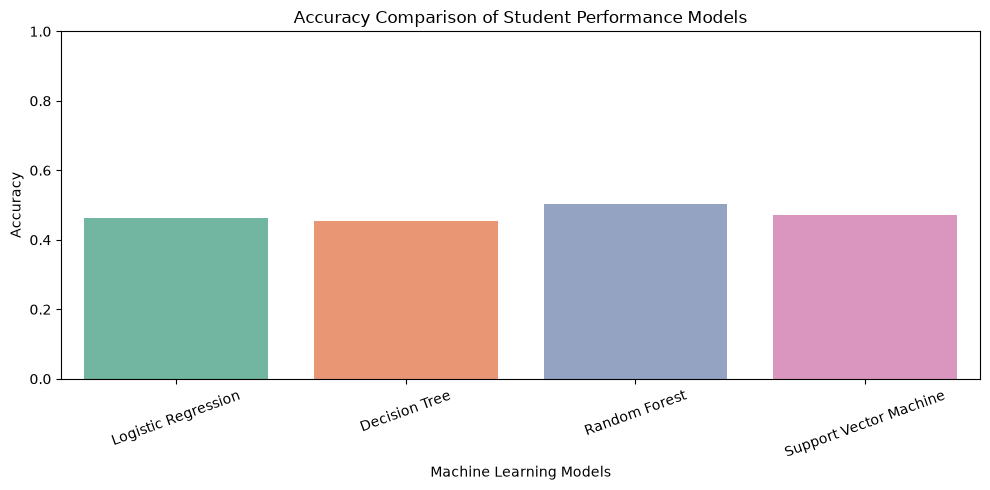

In [29]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy",
    hue="Model",
    palette="Set2",
    legend=False
)

plt.title("Accuracy Comparison of Student Performance Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

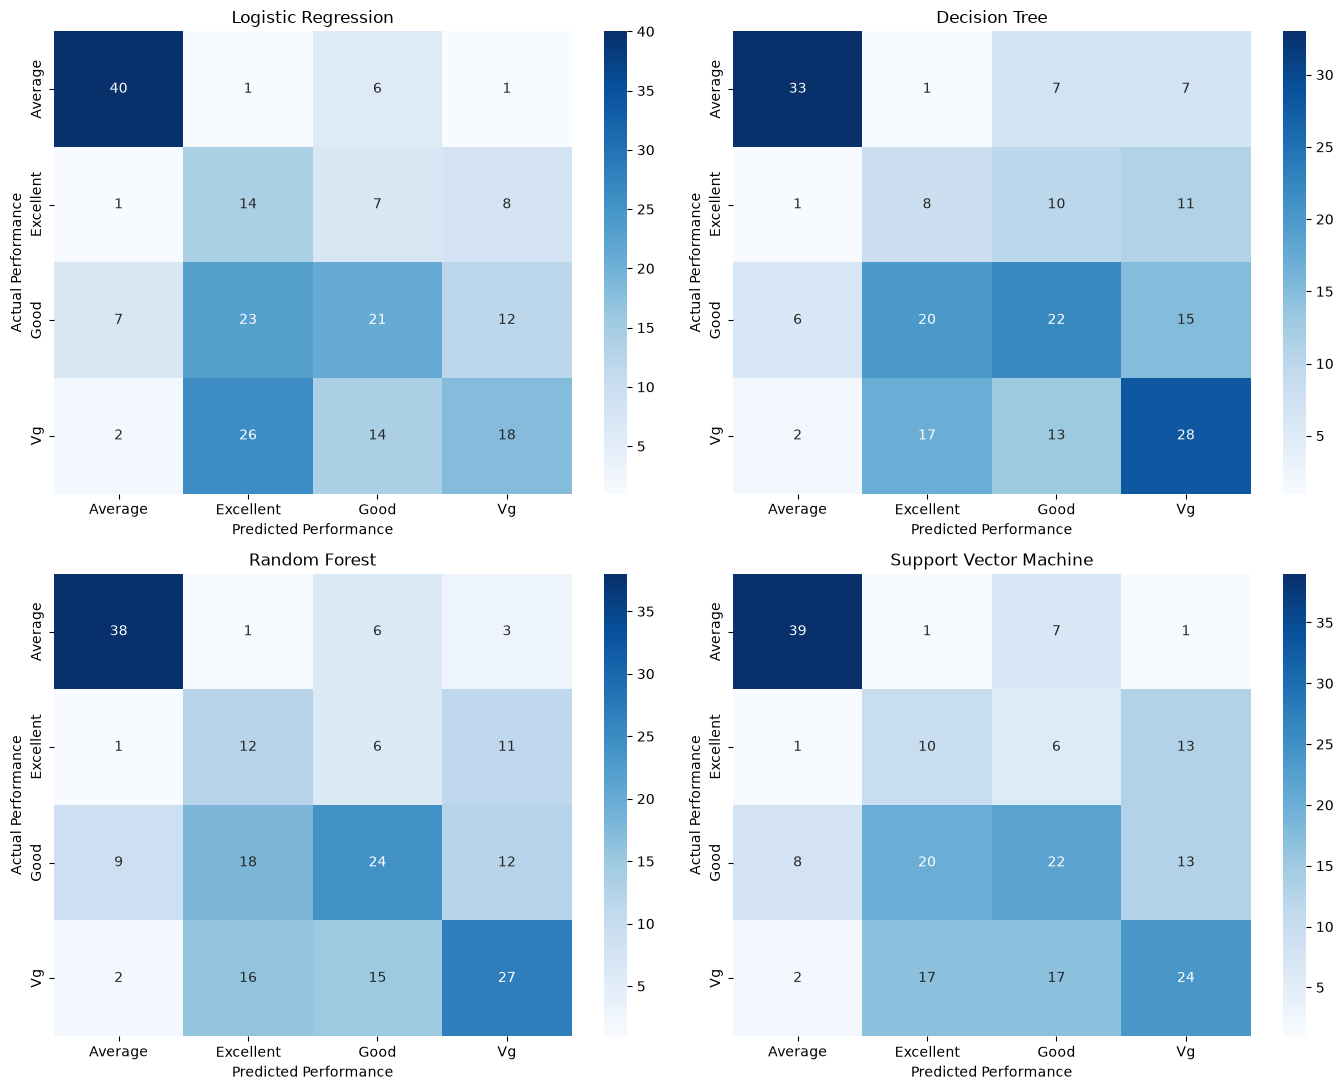

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()

class_labels = ["Average", "Excellent", "Good", "Vg"]

for ax, (name, pipeline) in zip(
    axes, trained_models.items()
):

    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Performance")
    ax.set_ylabel("Actual Performance")

plt.tight_layout()
plt.show()

In [31]:
results_df.to_csv(
    "../results/student_performance_model_comparison.csv",
    index=False
)

print("Student Performance results saved successfully!")

Student Performance results saved successfully!
